# 01 - Analyse des biais du dataset

Objectif : repérer ce qu'un modèle de prédiction de l'Elo pourrait apprendre d'autre que le niveau de jeu.

**Lecture des tests.** Un joueur apporte jusqu'à 5 parties : elles ne sont pas indépendantes. Tous les tests
ci-dessous regroupent donc les erreurs par joueur (écarts-types *cluster-robust*), sinon les p-valeurs seraient
trop optimistes. La part de variance expliquée (η²) indique la taille de l'effet : avec 4 200 parties, une p-valeur
faible peut correspondre à un effet négligeable.

Les graphiques sont enregistrés dans `figures/eda/`, au format 16:9.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from IPython.display import display

FIG_DIR = Path("figures/eda")
FIG_DIR.mkdir(parents=True, exist_ok=True)

INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3de"
BLUE, ORANGE = "#2a78d6", "#eb6834"
ALL_LABEL, NO_LB_LABEL = "Toutes les parties", "Sans leaderboard"
plt.rcParams.update({
    "figure.figsize": (13.33, 7.5), "figure.dpi": 90, "savefig.dpi": 200, "figure.facecolor": "white",
    "font.size": 15, "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.axisbelow": True, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 1, "xtick.color": INK_2, "ytick.color": INK, "text.color": INK,
    "xtick.bottom": False, "ytick.left": False, "axes.spines.top": False, "axes.spines.right": False,
    "axes.spines.left": False, "legend.frameon": False,
})

BINS = [100, 400, 700, 1000, 1300, 1600, 1900, np.inf]
BIN_LABELS = ["100-400", "400-700", "700-1000", "1000-1300", "1300-1600", "1600-1900", "1900+"]
COUNTRY_ORDER = ["BR", "DE", "FR", "IN", "US"]
COUNTRY_NAMES = {"BR": "Brésil", "DE": "Allemagne", "FR": "France", "IN": "Inde", "US": "États-Unis"}

games = pd.read_csv("data/games.csv", usecols=lambda c: c not in ("pgn", "moves"), keep_default_na=False)
games["accuracy"] = pd.to_numeric(games["accuracy"], errors="coerce")
games["no_accuracy"] = games["accuracy"].isna().astype(int)
games["player"] = games["username"].str.lower()
games["elo_bin"] = pd.cut(games["elo"], BINS, right=False, labels=BIN_LABELS).astype(str)
no_leaderboard = games[games["source"] != "leaderboard"]
print(f"{len(games)} parties, {games['player'].nunique()} joueurs")
print(f"Corrélation Elo / Elo de l'adversaire : {games['elo'].corr(games['opponent_elo']):.2f}")
display(games.groupby("source").agg(parties=("elo", "size"), joueurs=("player", "nunique"), elo_median=("elo", "median")))

4200 parties, 856 joueurs
Corrélation Elo / Elo de l'adversaire : 0.99


,parties,joueurs,elo_median
source,,,
country_list,201,44,418.0
leaderboard,101,21,2729.0
opponent,3898,791,1163.0


In [2]:
def dummies(df, column, reference=None):
    """Indicatrices d'une variable catégorielle, sans la modalité de référence."""
    reference = reference if reference is not None else sorted(df[column].unique())[0]
    return pd.get_dummies(df[column].astype(str), dtype=float).drop(columns=reference)


def joint_p(result, names):
    """Test de Wald joint : tous les coefficients `names` sont-ils nuls ?"""
    params = list(result.params.index)
    R = np.zeros((len(names), len(params)))
    for row, name in enumerate(names):
        R[row, params.index(name)] = 1
    return float(result.wald_test(R, use_f=True, scalar=True).pvalue)


def cluster_fit(model, df):
    groups = pd.factorize(df["player"])[0]
    return model.fit(cov_type="cluster", cov_kwds={"groups": groups}, **({"disp": 0} if model.__class__ is sm.Logit else {}))


def test_elo(df, column, label, min_n=30):
    """Elo ~ groupe : part de variance expliquée et p-valeur par joueur, sur les groupes d'au moins min_n parties."""
    sizes = df[column].value_counts()
    kept = df[df[column].isin(sizes[sizes >= min_n].index)]
    X = dummies(kept, column)
    result = cluster_fit(sm.OLS(kept["elo"], sm.add_constant(X)), kept)
    medians = kept.groupby(column)["elo"].median()
    return {"analyse": label, "parties": len(kept), "groupes": kept[column].nunique(), "eta2": result.rsquared,
            "p": joint_p(result, list(X.columns)), "écart des médianes": medians.max() - medians.min()}


def finish(fig, name):
    fig.tight_layout(rect=(0, 0, 1, 0.87))
    fig.savefig(FIG_DIR / f"{name}.png")
    plt.show()


def set_titles(ax, title, subtitle):
    ax.figure.text(0.015, 0.95, title, fontsize=22, fontweight="bold", va="center")
    ax.figure.text(0.015, 0.89, subtitle, fontsize=15, color=INK_2, va="center")


def box_style(color, widths=0.62):
    return dict(
        patch_artist=True, widths=widths, boxprops=dict(facecolor=color, edgecolor=color, alpha=0.32, linewidth=1.5),
        medianprops=dict(color=color, linewidth=3), whiskerprops=dict(color=color, linewidth=1.5),
        capprops=dict(color=color, linewidth=1.5),
        flierprops=dict(marker="o", markersize=3, markerfacecolor=INK_2, markeredgecolor="none", alpha=0.35),
    )


def elo_by_group(df, column, labels, title, subtitle, name, min_box=30):
    """Boîtes horizontales triées par médiane. Sous min_box parties, on montre les points : une boîte tromperait."""
    groups = df.groupby(column)["elo"]
    order = groups.median().sort_values().index
    fig, ax = plt.subplots()
    widths = 0.62 if len(order) > 3 else 0.35
    for position, group in enumerate(order):
        values = groups.get_group(group)
        if len(values) >= min_box:
            ax.boxplot(values, positions=[position], vert=False, **box_style(BLUE, widths))
        else:
            ax.plot(values, np.full(len(values), position), "o", color=BLUE, markersize=8, markeredgecolor="white", markeredgewidth=1.5, zorder=3)
    ax.axvline(df["elo"].median(), color=INK_2, linestyle="--", linewidth=1.5, zorder=1)
    top = len(order) - 0.4 + 0.07 * len(order)
    ax.text(df["elo"].median() + 15, top, "médiane globale", color=INK_2, fontsize=13, va="top")
    ax.set_yticks(range(len(order)), [f"{labels.get(g, g)}  (n={len(groups.get_group(g))})" for g in order],
                  fontsize=15 if len(order) <= 12 else 12.5)
    ax.set_ylim(-0.6, top)
    ax.set_xlabel("Elo rapide dans la partie")
    ax.grid(axis="y", visible=False)
    set_titles(ax, title, subtitle)
    finish(fig, name)


def player_bootstrap_ci(df, column, order, n_boot=2000, seed=42):
    """Intervalle à 95 % du taux d'absence, en rééchantillonnant les joueurs et non les parties."""
    rng = np.random.default_rng(seed)
    out = {}
    for group in order:
        by_player = df[df[column] == group].groupby("player")["no_accuracy"].agg(["sum", "size"]).to_numpy()
        draws = rng.integers(0, len(by_player), (n_boot, len(by_player)))
        rates = by_player[draws, 0].sum(axis=1) / by_player[draws, 1].sum(axis=1)
        out[group] = (by_player[:, 0].sum() / by_player[:, 1].sum(), *np.percentile(rates, [2.5, 97.5]))
    return out


def missing_rate_plot(column, order, labels, xlabel, title, subtitle, name):
    """Compare le taux d'absence avec et sans leaderboard, groupe par groupe."""
    fig, ax = plt.subplots()
    for df, color, label, shift, marker in ((games, BLUE, ALL_LABEL, -0.12, "o"), (no_leaderboard, ORANGE, NO_LB_LABEL, 0.12, "s")):
        ci = player_bootstrap_ci(df, column, order)
        rate = np.array([ci[g][0] for g in order]) * 100
        low = np.array([ci[g][1] for g in order]) * 100
        high = np.array([ci[g][2] for g in order]) * 100
        x = np.arange(len(order)) + shift
        ax.errorbar(x, rate, yerr=[rate - low, high - rate], fmt=marker, color=color, markersize=11, markeredgecolor="white",
                    markeredgewidth=2, elinewidth=2.5, label=label)
    ax.axhline(games["no_accuracy"].mean() * 100, color=INK_2, linestyle="--", linewidth=1.5)
    ax.set_xticks(range(len(order)), [labels.get(g, g) for g in order])
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Parties sans accuracy (%)")
    ax.set_ylim(30, 90)
    ax.grid(axis="x", visible=False)
    ax.legend(loc="lower left")
    set_titles(ax, title, subtitle)
    finish(fig, name)

## 1. Elo par pays

**À garder en tête :** chaque pays a le même quota dans chaque tranche d'Elo. L'absence de lien pays → Elo *entre tranches*
est donc garantie par construction : elle décrit l'échantillon, pas la population chess.com. Ce qui reste à vérifier, c'est
s'il subsiste un lien **à l'intérieur des tranches**, et si les parties leaderboard (Elo très élevés, plafonnées à 25 % par case)
en créent un.

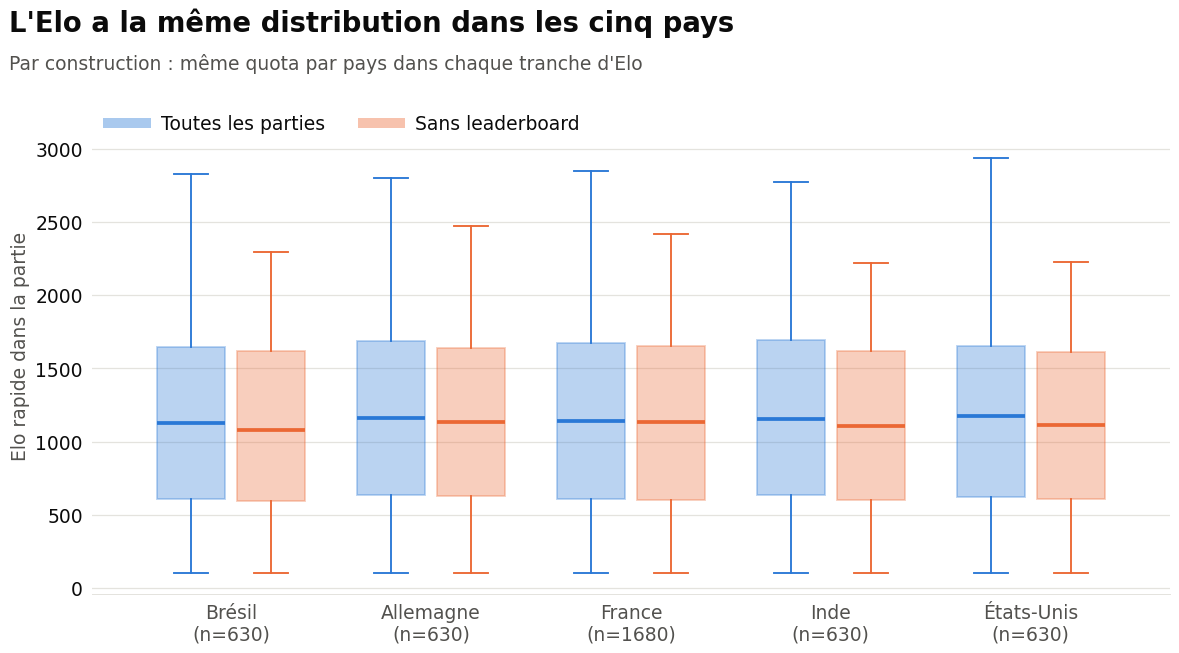

count    mean    25%     50%     75%     max
                   country                                               
Toutes les parties BR        630.0  1165.0  610.0  1124.0  1644.0  2824.0
                   DE        630.0  1172.0  638.0  1162.0  1689.0  2798.0
                   FR       1680.0  1162.0  608.0  1144.0  1674.0  2846.0
                   IN        630.0  1168.0  635.0  1154.0  1691.0  2772.0
                   US        630.0  1171.0  621.0  1175.0  1653.0  2938.0
Sans leaderboard   BR        610.0  1113.0  594.0  1079.0  1617.0  2294.0
                   DE        615.0  1135.0  628.0  1131.0  1638.0  2469.0
                   FR       1660.0  1143.0  600.0  1135.0  1652.0  2414.0
                   IN        607.0  1111.0  604.0  1107.0  1622.0  2222.0
                   US        607.0  1110.0  608.0  1114.0  1612.0  2223.0

In [3]:
fig, ax = plt.subplots()
for df, color, label, shift in ((games, BLUE, ALL_LABEL, -0.2), (no_leaderboard, ORANGE, NO_LB_LABEL, 0.2)):
    for position, country in enumerate(COUNTRY_ORDER):
        style = box_style(color, widths=0.34)
        ax.boxplot(df.loc[df["country"] == country, "elo"], positions=[position + shift], **style)
    ax.plot([], [], color=color, linewidth=8, alpha=0.4, label=label)
ax.set_xticks(range(5), [f"{COUNTRY_NAMES[c]}\n(n={(games['country'] == c).sum()})" for c in COUNTRY_ORDER])
ax.set_ylabel("Elo rapide dans la partie")
ax.set_ylim(top=3350)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", ncols=2)
set_titles(ax, "L'Elo a la même distribution dans les cinq pays", "Par construction : même quota par pays dans chaque tranche d'Elo")
finish(fig, "fig01_elo_par_pays")

summary = pd.concat({ALL_LABEL: games.groupby("country")["elo"].describe(), NO_LB_LABEL: no_leaderboard.groupby("country")["elo"].describe()})
display(summary[["count", "mean", "25%", "50%", "75%", "max"]].round(0))

### Le lien subsiste-t-il à l'intérieur des tranches ?

In [4]:
rows = []
for label, df in ((ALL_LABEL, games), (NO_LB_LABEL, no_leaderboard)):
    rows.append({"périmètre": label, "tranche": "toutes", **test_elo(df, "country", "")})
    for elo_bin in BIN_LABELS:
        rows.append({"périmètre": label, "tranche": elo_bin, **test_elo(df[df["elo_bin"] == elo_bin], "country", "")})
within = pd.DataFrame(rows).drop(columns=["analyse", "groupes"])
display(within.round({"eta2": 4, "p": 4, "écart des médianes": 0}))

leaderboard_share = games[games["elo_bin"] == "1900+"].groupby("country")["source"].apply(lambda s: (s == "leaderboard").mean()).round(3)
print("Part de parties leaderboard dans la tranche 1900+ :", leaderboard_share.to_dict())

,périmètre,tranche,parties,eta2,p,écart des médianes
0,Toutes les parties,toutes,4200,0.0000,0.9998,50.0
1,Toutes les parties,100-400,600,0.0127,0.6863,70.0
2,Toutes les parties,400-700,600,0.0053,0.8795,48.0
3,Toutes les parties,700-1000,600,0.0124,0.6050,65.0
4,Toutes les parties,1000-1300,600,0.0181,0.1842,50.0
5,Toutes les parties,1300-1600,600,0.0059,0.7963,35.0
6,Toutes les parties,1600-1900,600,0.0356,0.0221,59.0
7,Toutes les parties,1900+,600,0.0206,0.5735,56.0
8,Sans leaderboard,toutes,4099,0.0006,0.9700,56.0
9,Sans leaderboard,100-400,600,0.0127,0.6863,70.0


Part de parties leaderboard dans la tranche 1900+ : {'BR': 0.222, 'DE': 0.167, 'FR': 0.083, 'IN': 0.256, 'US': 0.256}


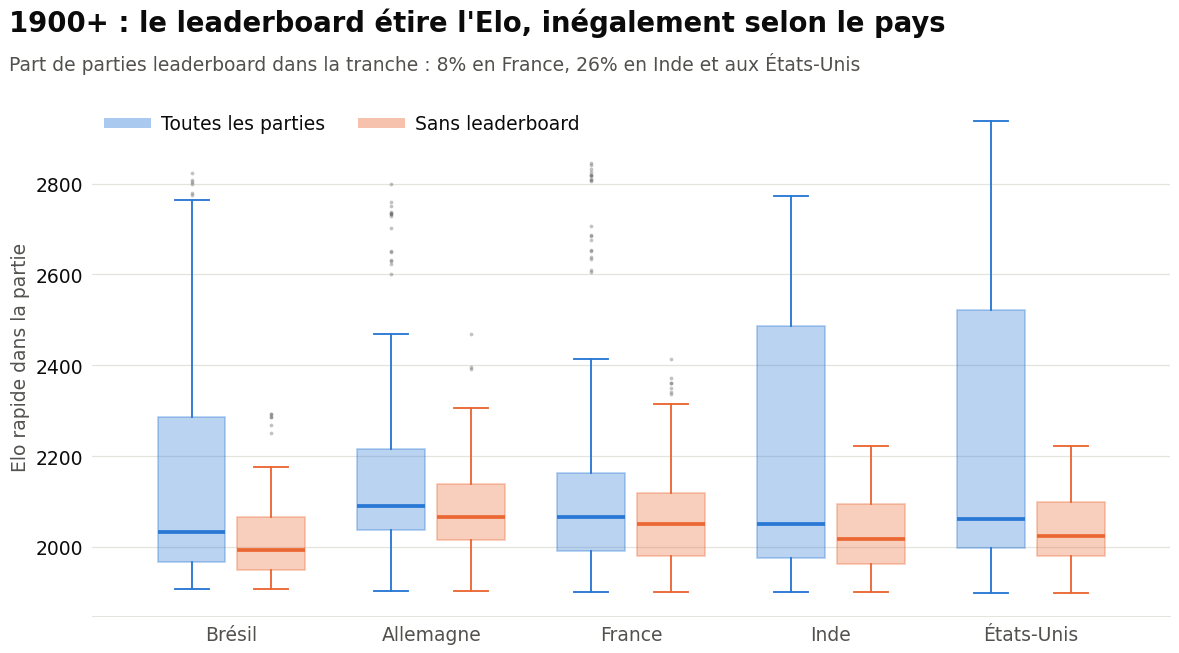

In [5]:
top = games[games["elo_bin"] == "1900+"]
top_no_lb = no_leaderboard[no_leaderboard["elo_bin"] == "1900+"]
fig, ax = plt.subplots()
for df, color, label, shift in ((top, BLUE, ALL_LABEL, -0.2), (top_no_lb, ORANGE, NO_LB_LABEL, 0.2)):
    for position, country in enumerate(COUNTRY_ORDER):
        style = box_style(color, widths=0.34)
        ax.boxplot(df.loc[df["country"] == country, "elo"], positions=[position + shift], **style)
    ax.plot([], [], color=color, linewidth=8, alpha=0.4, label=label)
ax.set_xticks(range(5), [COUNTRY_NAMES[c] for c in COUNTRY_ORDER])
ax.set_ylabel("Elo rapide dans la partie")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", ncols=2)
set_titles(ax, "1900+ : le leaderboard étire l'Elo, inégalement selon le pays",
           f"Part de parties leaderboard dans la tranche : {leaderboard_share['FR']:.0%} en France, "
           f"{leaderboard_share['IN']:.0%} en Inde et aux États-Unis")
finish(fig, "fig02_elo_par_pays_1900plus")

## 2. Elo par ouverture

`opening_name` compte beaucoup de variantes : les 20 plus fréquentes ne couvrent qu'une partie du dataset (voir ci-dessous).

1826 noms d'ouvertures ; les 20 premiers couvrent 16.8% des parties.


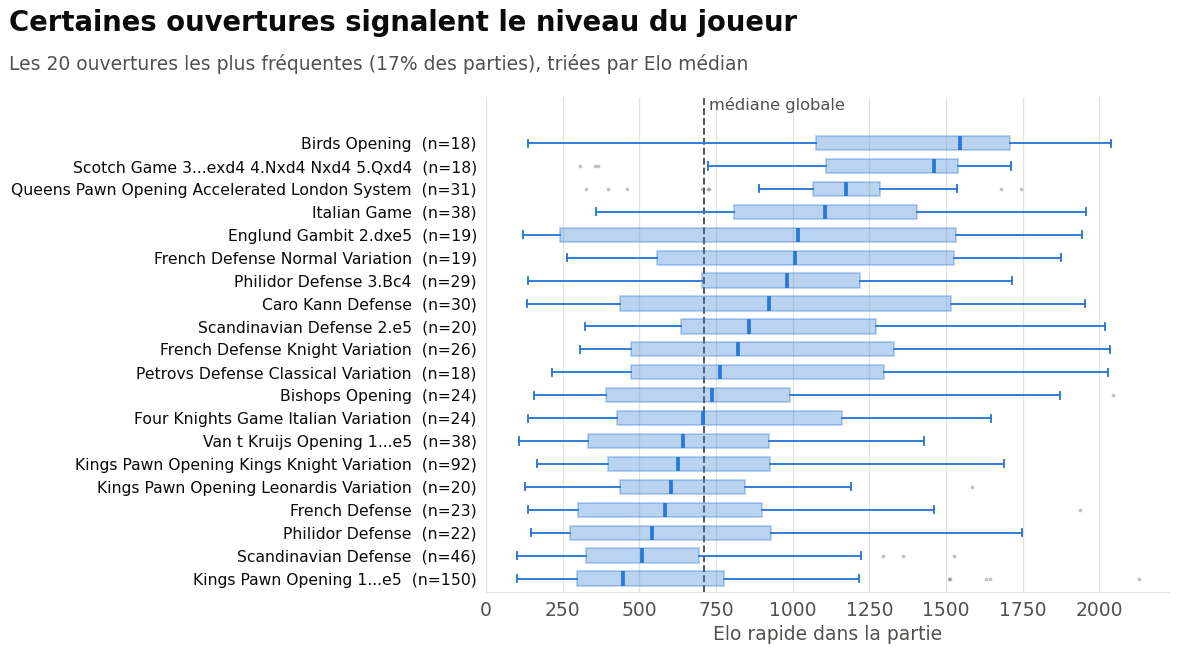

In [6]:
named = games[games["opening_name"].ne("Undefined") & games["opening_name"].ne("")]
top_openings = named["opening_name"].value_counts().head(20).index
openings = named[named["opening_name"].isin(top_openings)]
coverage = len(openings) / len(games)
print(f"{named['opening_name'].nunique()} noms d'ouvertures ; les 20 premiers couvrent {coverage:.1%} des parties.")
elo_by_group(openings, "opening_name", {}, "Certaines ouvertures signalent le niveau du joueur",
             f"Les 20 ouvertures les plus fréquentes ({coverage:.0%} des parties), triées par Elo médian", "fig03_elo_par_ouverture", min_box=15)

## 3. Elo par couleur, type de fin de partie et cadence

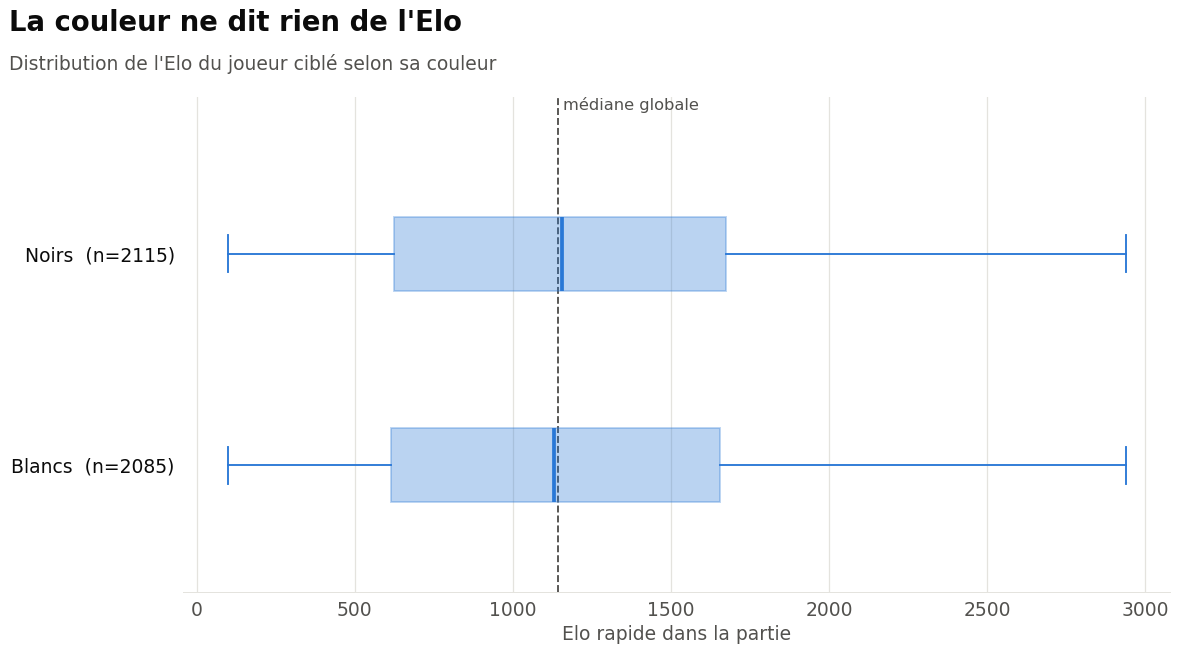

In [7]:
elo_by_group(games, "color", {"white": "Blancs", "black": "Noirs"}, "La couleur ne dit rien de l'Elo",
             "Distribution de l'Elo du joueur ciblé selon sa couleur", "fig04_elo_par_couleur")

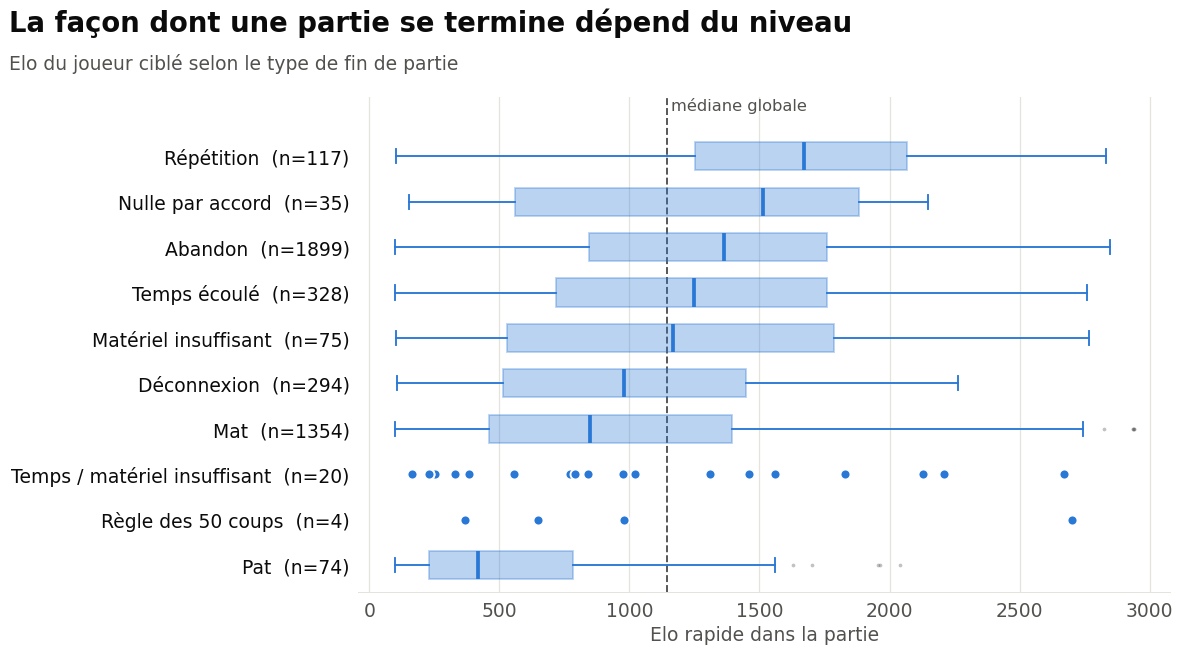

In [8]:
TERMINATION_LABELS = {
    "abandon": "Abandon", "mat": "Mat", "temps": "Temps écoulé", "deconnexion": "Déconnexion", "nulle_accord": "Nulle par accord",
    "nulle_repetition": "Répétition", "pat": "Pat", "materiel_insuffisant": "Matériel insuffisant",
    "regle_50_coups": "Règle des 50 coups", "temps_vs_materiel_insuffisant": "Temps / matériel insuffisant",
}
elo_by_group(games, "termination", TERMINATION_LABELS, "La façon dont une partie se termine dépend du niveau",
             "Elo du joueur ciblé selon le type de fin de partie", "fig05_elo_par_fin_de_partie")

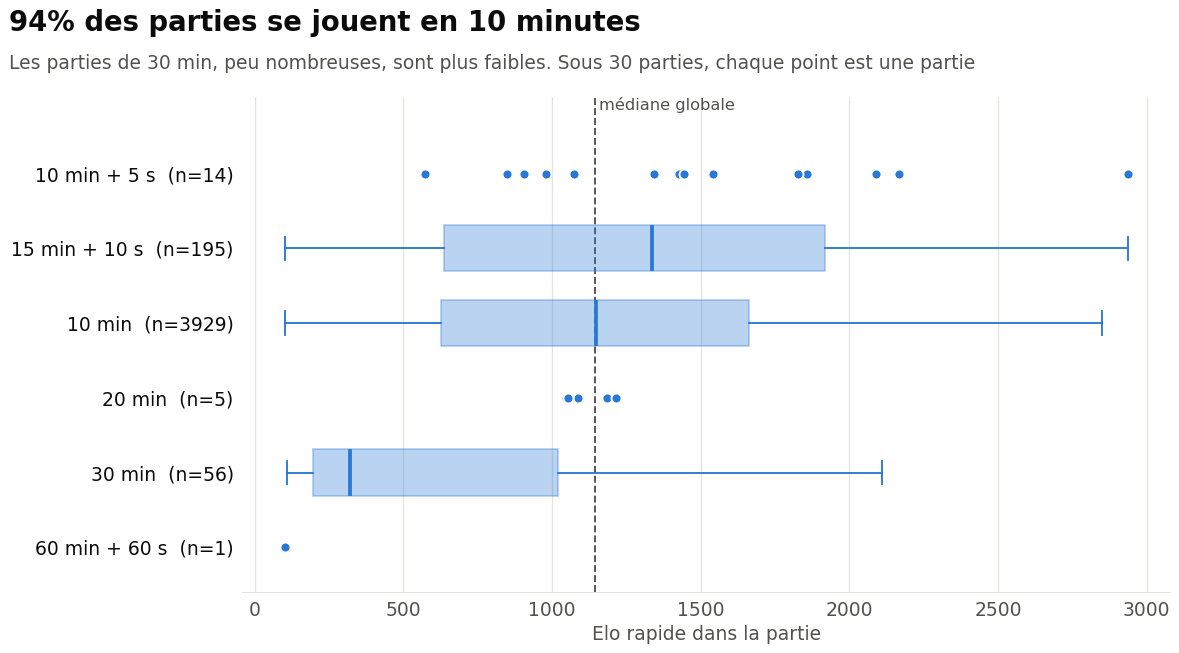

In [9]:
TIME_LABELS = {"600": "10 min", "600+5": "10 min + 5 s", "900+10": "15 min + 10 s", "1200": "20 min", "1800": "30 min", "3600+60": "60 min + 60 s"}
elo_by_group(games, "time_control", TIME_LABELS, f"{(games['time_control'] == '600').mean():.0%} des parties se jouent en 10 minutes",
             "Les parties de 30 min, peu nombreuses, sont plus faibles. Sous 30 parties, chaque point est une partie", "fig06_elo_par_cadence")

In [10]:
elo_tests = pd.DataFrame([
    test_elo(games, "country", "Pays (toutes parties)"),
    test_elo(no_leaderboard, "country", "Pays (sans leaderboard)"),
    test_elo(games, "source", "Origine du joueur (source)"),
    test_elo(games, "color", "Couleur"),
    test_elo(openings, "opening_name", "Ouverture (top 20)", min_n=15),
    test_elo(games, "termination", "Type de fin de partie"),
    test_elo(games, "time_control", "Cadence"),
])
display(elo_tests.sort_values("eta2", ascending=False).round({"eta2": 3, "p": 4, "écart des médianes": 0}))

,analyse,parties,groupes,eta2,p,écart des médianes
4,Ouverture (top 20),705,20,0.217,0.0000,1098.0
2,Origine du joueur (source),4200,3,0.190,0.0000,2311.0
5,Type de fin de partie,4176,8,0.094,0.0000,1252.0
6,Cadence,4180,3,0.010,0.0000,1018.0
1,Pays (sans leaderboard),4099,5,0.001,0.9700,56.0
3,Couleur,4200,2,0.000,0.4939,26.0
0,Pays (toutes parties),4200,5,0.000,0.9998,50.0


## 4. L'absence d'accuracy dépend-elle du pays ou de l'Elo ?

Une valeur manquante n'est gênante que si elle n'est pas due au hasard : si l'absence dépend du pays ou de l'Elo, le simple
fait qu'elle manque devient une information pour le modèle, et les parties où elle est présente ne représentent plus le dataset.
Les intervalles à 95 % sont obtenus en rééchantillonnant les joueurs.

Parties sans accuracy : 71.5%


,size,mean
source,,
country_list,201,0.711
leaderboard,101,0.020
opponent,3898,0.733


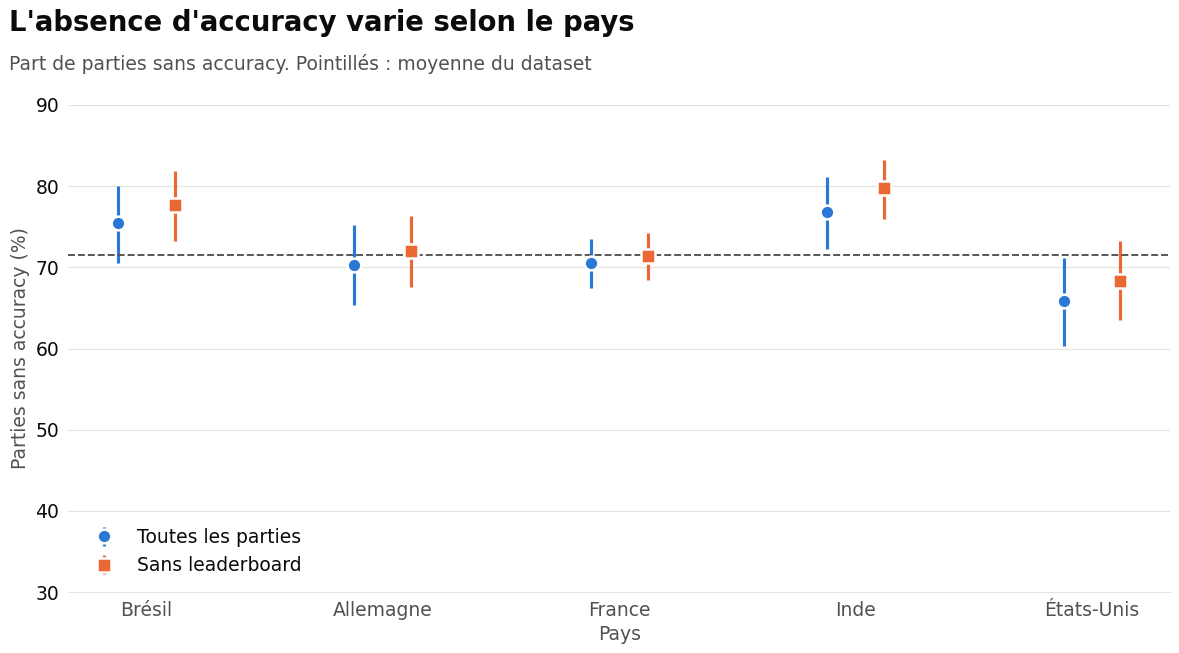

In [11]:
print(f"Parties sans accuracy : {games['no_accuracy'].mean():.1%}")
display(games.groupby("source")["no_accuracy"].agg(["size", "mean"]).round(3))
missing_rate_plot("country", COUNTRY_ORDER, COUNTRY_NAMES, "Pays", "L'absence d'accuracy varie selon le pays",
                  "Part de parties sans accuracy. Pointillés : moyenne du dataset", "fig07_absence_accuracy_par_pays")

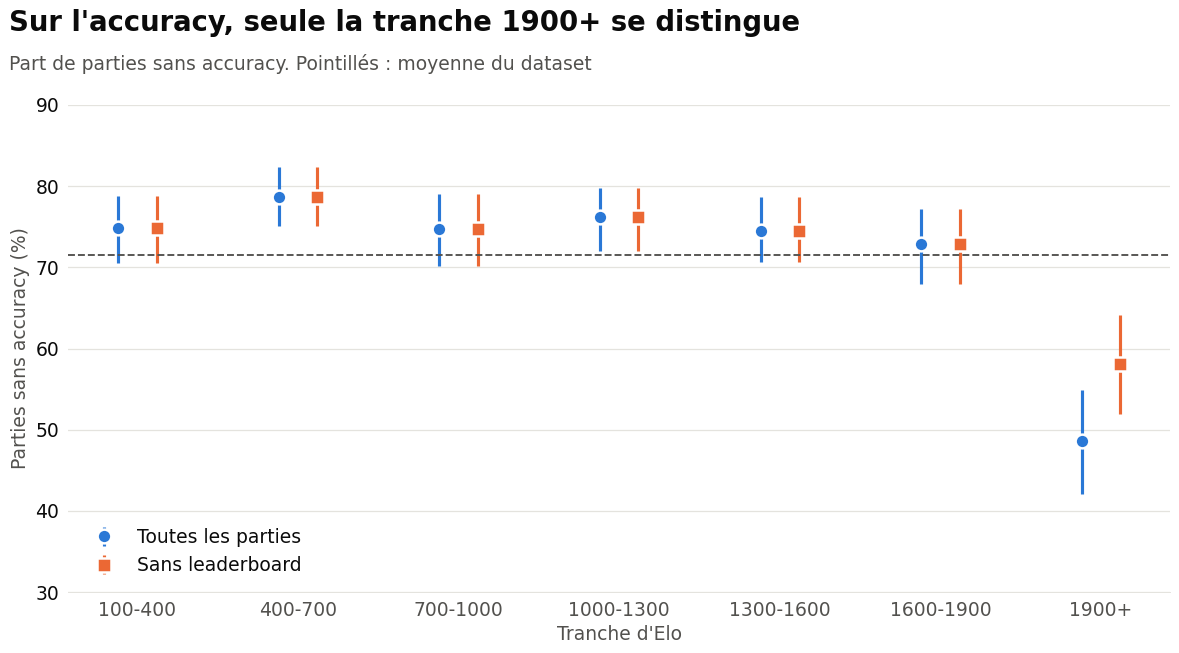

In [12]:
missing_rate_plot("elo_bin", BIN_LABELS, {}, "Tranche d'Elo", "Sur l'accuracy, seule la tranche 1900+ se distingue",
                  "Part de parties sans accuracy. Pointillés : moyenne du dataset", "fig08_absence_accuracy_par_elo")

### Effets conjoints : régression logistique

In [13]:
def missing_model(df):
    """P(accuracy absente) ~ pays + tranche d'Elo, avec les erreurs regroupées par joueur."""
    countries, elo_bins = dummies(df, "country", "FR"), dummies(df, "elo_bin", "1000-1300")
    X = sm.add_constant(pd.concat([countries, elo_bins], axis=1))
    result = cluster_fit(sm.Logit(df["no_accuracy"], X), df)
    return result, list(countries.columns), list(elo_bins.columns)


models = {ALL_LABEL: missing_model(games), NO_LB_LABEL: missing_model(no_leaderboard)}
joint = pd.DataFrame({
    label: {"p pays (à Elo égal)": joint_p(res, c), "p Elo (à pays égal)": joint_p(res, b), "pseudo-R²": res.prsquared}
    for label, (res, c, b) in models.items()
})
display(joint.round(4))

ratios = pd.concat({
    label: pd.DataFrame({"OR": np.exp(res.params), "bas": np.exp(res.conf_int()[0]), "haut": np.exp(res.conf_int()[1]), "p": res.pvalues}).drop("const")
    for label, (res, _, _) in models.items()
})
display(ratios.round(3))

,Toutes les parties,Sans leaderboard
p pays (à Elo égal),0.0045,0.0007
p Elo (à pays égal),0.0000,0.0000
pseudo-R²,0.0390,0.0205


OR    bas   haut      p
Toutes les parties BR         1.295  0.967  1.734  0.083
                   DE         0.989  0.761  1.285  0.934
                   IN         1.406  1.070  1.846  0.014
                   US         0.798  0.613  1.039  0.094
                   100-400    0.930  0.685  1.263  0.642
                   1300-1600  0.914  0.672  1.243  0.565
                   1600-1900  0.838  0.613  1.146  0.269
                   1900+      0.294  0.211  0.410  0.000
                   400-700    1.155  0.853  1.563  0.351
                   700-1000   0.922  0.689  1.234  0.584
Sans leaderboard   BR         1.387  1.039  1.852  0.026
                   DE         1.027  0.793  1.329  0.843
                   IN         1.563  1.195  2.043  0.001
                   US         0.850  0.653  1.107  0.229
                   100-400    0.930  0.684  1.264  0.643
                   1300-1600  0.914  0.671  1.243  0.565
                   1600-1900  0.838  0.613  1.146  0.268
                   1900+      0.434  0.312  0.606  0.000
                   400-700    1.155  0.853  1.563  0.351
                   700-1000   0.922  0.688  1.235  0.585

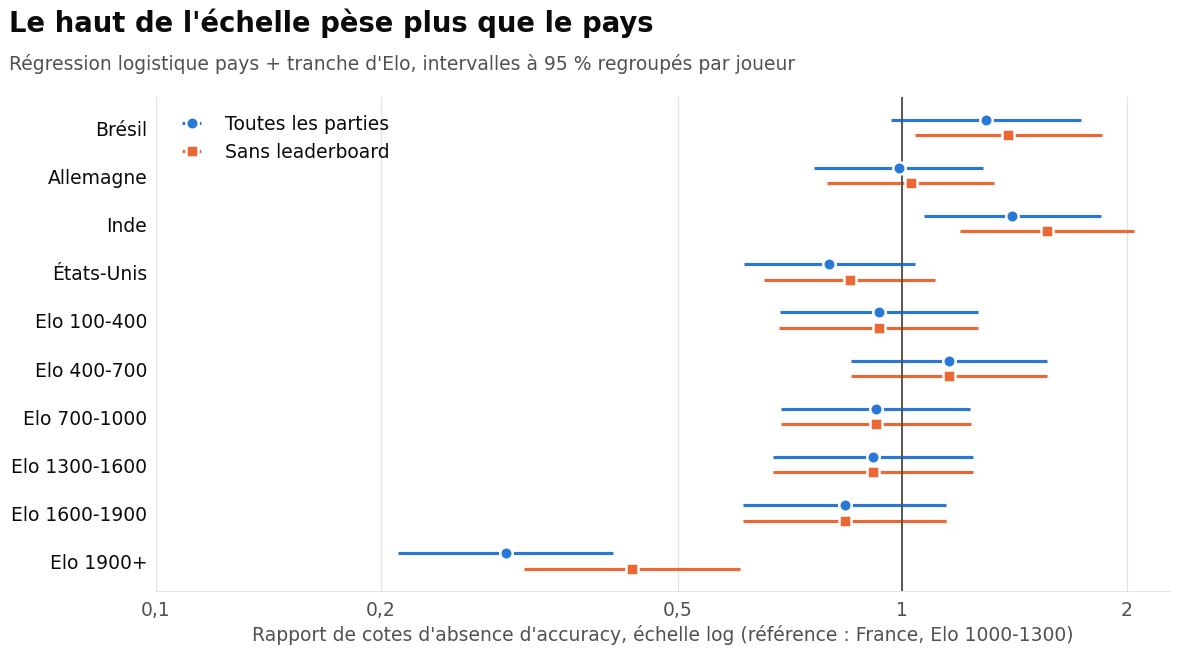

In [14]:
terms = [("BR", "Brésil"), ("DE", "Allemagne"), ("IN", "Inde"), ("US", "États-Unis"),
         ("100-400", "Elo 100-400"), ("400-700", "Elo 400-700"), ("700-1000", "Elo 700-1000"),
         ("1300-1600", "Elo 1300-1600"), ("1600-1900", "Elo 1600-1900"), ("1900+", "Elo 1900+")]
fig, ax = plt.subplots()
for label, color, shift, marker in ((ALL_LABEL, BLUE, 0.16, "o"), (NO_LB_LABEL, ORANGE, -0.16, "s")):
    table = ratios.loc[label]
    y = np.arange(len(terms))[::-1] + shift
    values = table.loc[[t for t, _ in terms]]
    ax.errorbar(values["OR"], y, xerr=[values["OR"] - values["bas"], values["haut"] - values["OR"]], fmt=marker, color=color, markersize=10,
                markeredgecolor="white", markeredgewidth=2, elinewidth=2.5, label=label)
ax.axvline(1, color=INK_2, linewidth=1.5)
ax.set_xscale("log")
ax.set_xticks([0.1, 0.2, 0.5, 1, 2], ["0,1", "0,2", "0,5", "1", "2"])
ax.minorticks_off()
ax.set_yticks(range(len(terms)), [name for _, name in terms][::-1])
ax.set_xlabel("Rapport de cotes d'absence d'accuracy, échelle log (référence : France, Elo 1000-1300)")
ax.grid(axis="y", visible=False)
ax.legend(loc="upper left")
set_titles(ax, "Le haut de l'échelle pèse plus que le pays", "Régression logistique pays + tranche d'Elo, intervalles à 95 % regroupés par joueur")
finish(fig, "fig09_absence_accuracy_regression")

### L'absence est-elle une habitude de joueur ?

In [15]:
five_games = games.groupby("player").filter(lambda g: len(g) == 5)
with_accuracy = 5 - five_games.groupby("player")["no_accuracy"].sum()
rate = 1 - five_games["no_accuracy"].mean()
observed = with_accuracy.value_counts(normalize=True).sort_index()
expected = pd.Series(np.random.default_rng(42).binomial(5, rate, 1_000_000)).value_counts(normalize=True).sort_index()
display(pd.DataFrame({"observé": observed, "si indépendant": expected}).rename_axis("parties avec accuracy, sur 5").round(3))

,observé,si indépendant
"parties avec accuracy, sur 5",,
0,0.305,0.187
1,0.296,0.373
2,0.220,0.296
3,0.079,0.118
4,0.049,0.023
5,0.051,0.002


## Conclusions

**1. Pays → Elo : pas de lien dans le dataset, mais c'est le résultat des quotas.**
- Globalement, le pays n'explique rien : η² < 0,001 (p = 0,9998), et η² = 0,0006 sans le leaderboard (p = 0,97).
- Ce résultat ne dit rien de la population chess.com : les quotas imposent cet équilibre. Il garantit seulement qu'un modèle ne peut pas gagner en précision en devinant l'Elo moyen d'un pays.
- À l'intérieur des tranches, les médianes s'écartent d'au plus 74 points. Une seule tranche sur 7 passe sous p = 0,05 (1600-1900, p = 0,022, η² = 0,036), et elle ne résiste pas à une correction de Bonferroni.
- Point de vigilance : le leaderboard pèse 8 % de la tranche 1900+ en France, contre 26 % en Inde et aux États-Unis. Le haut de cette tranche n'est donc pas comparable d'un pays à l'autre.

**2. Autres variables : plusieurs sont liées à l'Elo.**

| Variable | η² | Écart des médianes | Lecture |
|---|---|---|---|
| Ouverture (top 20, 17 % des parties) | 0,22 | 1 098 | Lien fort sur ces parties |
| `source` | 0,19 | 2 311 | Lien créé par l'échantillonnage |
| Type de fin de partie | 0,09 | 1 252 | Répétitions en haut, pats en bas |
| Cadence | 0,01 | 1 018 | Effet global faible : 94 % des parties sont en 10 min |
| Couleur | 0,00 | 26 | Aucun lien (p = 0,49) |

**3. L'absence d'accuracy n'est pas due au hasard : elle dépend de l'Elo et du pays.**
- Elle touche 71,5 % des parties.
- **Elo (p < 0,001) :** l'effet est un seuil, pas une pente. L'accuracy manque dans 73 à 79 % des parties sous 1900, contre 49 % en 1900+. L'effet subsiste sans le leaderboard (58 %).
- **Pays, à Elo égal (p = 0,0045, et 0,0007 sans leaderboard) :** Inde 77 %, Brésil 75 %, France et Allemagne 70 %, États-Unis 66 %.
- **Leaderboard :** l'accuracy n'y manque que dans 2 % des parties.
- **Joueurs :** l'absence dépend aussi du joueur. 5 % des joueurs à 5 parties ont l'accuracy sur toutes, contre 0,2 % attendus si les parties étaient indépendantes.
- Le pseudo-R² reste faible (0,04) : pays et Elo n'expliquent qu'une petite part de l'absence. Ces données ne permettent pas d'en identifier la cause.

**Conséquences pour le modèle**
- Ne pas utiliser `accuracy` ni son absence comme variable : cela donnerait au modèle un indice sur le pays et sur le haut de l'échelle. Les variables Stockfish, calculées sur toutes les parties, évitent ce problème.
- Exclure `source` (artefact d'échantillonnage), `opponent_elo` (corrélation de 0,99 avec l'Elo) et `pgn` (ses en-têtes contiennent l'Elo).
- Vérifier les performances par pays, et les recalculer sans le leaderboard pour la tranche 1900+.
- Ouverture et fin de partie ne sont pas à exclure d'office, car elles reflètent en partie le niveau de jeu. Il reste à décider si le modèle peut s'y appuyer, et à vérifier qu'elles ne servent pas d'indice indirect du pays : ce lien n'a pas été testé ici.